# MG1: Palia: what did each update do to player numbers?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

sc = pd.read_csv("data/steamcharts_monthly.csv")
events = pd.read_csv("data/palia_events.csv", parse_dates=["date"])

palia = sc[sc["game"] == "Palia"].copy()
palia["month"] = pd.to_datetime(palia["month"])
palia = palia.set_index("month")["avg_players"]

content = events[events["event_type"] == "content"].copy()
content["month"] = content["date"].dt.to_period("M").dt.to_timestamp()
content[["date", "event"]]

,date,event
2,2025-05-13,PS5 and Xbox launch + Elderwood expansion
3,2025-06-12,Radiance Rising update (patch 0.192)
5,2025-09-10,Of Barns & Briars update (patch 0.195)
10,2026-05-12,Royal Highlands expansion


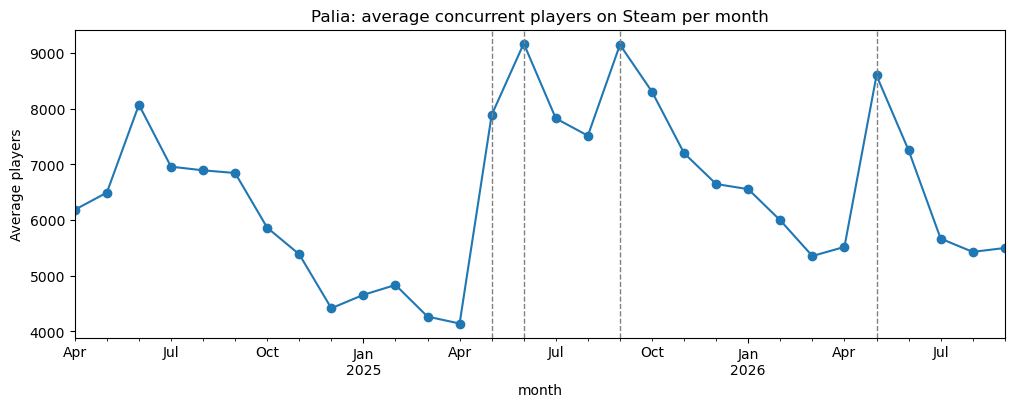

In [2]:
ax = palia.plot(figsize=(12, 4), marker="o",
                title="Palia: average concurrent players on Steam per month")
for _, e in content.iterrows():
    ax.axvline(e["date"], color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("Average players")
plt.show()

In [3]:
rows = []
for _, e in content.iterrows():
    m = e["month"]
    before = palia.get(m - pd.DateOffset(months=1))
    after3 = palia.get(m + pd.DateOffset(months=3))
    rows.append({"event": e["event"], "month": m.strftime("%Y-%m"),
                 "players_month_before": round(before),
                 "players_event_month": round(palia[m]),
                 "change_%": round((palia[m] / before - 1) * 100, 1),
                 "after_3_months_vs_before_%": round((after3 / before - 1) * 100, 1)})
impact = pd.DataFrame(rows)
impact

,event,month,players_month_before,players_event_month,change_%,after_3_months_vs_before_%
0,PS5 and Xbox launch + Elderwood expansion,2025-05,4141,7889,90.5,81.5
1,Radiance Rising update (patch 0.192),2025-06,7889,9172,16.3,16.0
2,Of Barns & Briars update (patch 0.195),2025-09,7516,9150,21.7,-11.6
3,Royal Highlands expansion,2026-05,5517,8599,55.8,-1.6


# MG2: Dota 2: which regions play at which time of day?

In [4]:
d = pd.read_csv("data/dota_matches_clean.csv", parse_dates=["start_time_utc"])
d["hour_utc"] = d["start_time_utc"].dt.hour

def area(region):
    r = str(region).upper()
    if r.startswith("PW"):
        return "China"
    if r in {"STOCKHOLM", "EUROPE", "AUSTRIA", "WARSAW"}:
        return "Europe"
    if r in {"SINGAPORE"}:
        return "SE Asia"
    if r in {"PERU", "BRAZIL", "CHILE", "ARGENTINA"}:
        return "South America"
    if r in {"US EAST", "US WEST"}:
        return "North America"
    if r == "UNKNOWN":
        return "Unknown"
    return "Other"

d["area"] = d["region"].map(area)
print(d["area"].value_counts())
print("\nRegions grouped as 'Other':", sorted(d.loc[d["area"] == "Other", "region"].unique()))

area
Europe           35086
SE Asia          13404
South America     8510
China             5759
North America     4779
Unknown           3496
Other             1881
Name: count, dtype: int64

Regions grouped as 'Other': ['AUSTRALIA', 'DUBAI', 'JAPAN', 'SOUTHAFRICA']


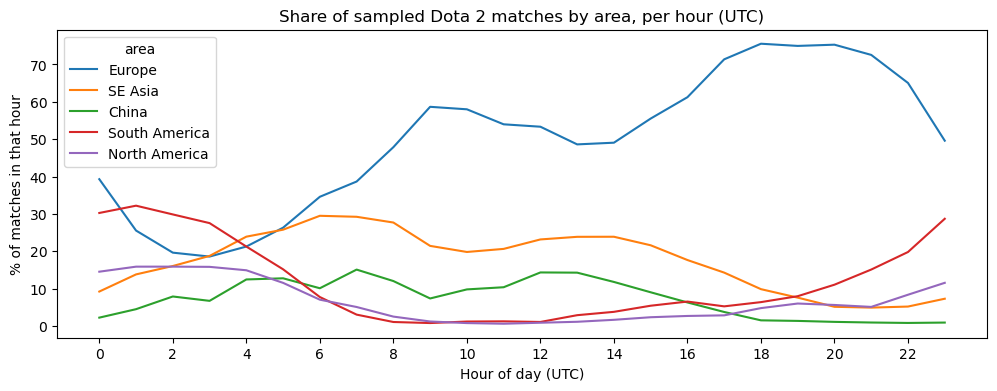

area,Europe,SE Asia,China,South America,North America
hour_utc,,,,,
0,39.3,9.2,2.2,30.2,14.5
1,25.5,13.8,4.5,32.2,15.9
2,19.6,16.0,7.9,29.8,15.9
3,18.6,18.7,6.7,27.5,15.8
4,21.2,23.9,12.4,21.2,14.9
5,26.3,25.8,12.7,15.1,11.5
6,34.6,29.5,10.1,7.7,7.0
7,38.7,29.2,15.1,3.0,5.0
8,47.9,27.7,12.0,1.0,2.5


In [5]:
mix = pd.crosstab(d["hour_utc"], d["area"], normalize="index") * 100
cols = ["Europe", "SE Asia", "China", "South America", "North America"]

ax = mix[cols].plot(figsize=(12, 4), title="Share of sampled Dota 2 matches by area, per hour (UTC)")
ax.set_xlabel("Hour of day (UTC)")
ax.set_ylabel("% of matches in that hour")
ax.set_xticks(range(0, 24, 2))
plt.show()
mix[cols].round(1)

# MG3: Match length by skill level and game mode

In [6]:
MEDALS = {1: "Herald", 2: "Guardian", 3: "Crusader", 4: "Archon",
          5: "Legend", 6: "Ancient", 7: "Divine", 8: "Immortal"}
order = [m for m in MEDALS.values() if m in set((d["avg_rank_tier"] // 10).map(MEDALS))]

d["medal"] = (d["avg_rank_tier"] // 10).map(MEDALS)
d["minutes"] = d["duration_sec"] / 60

main = d[d["game_mode_name"].isin(["All Draft", "Turbo"])]
length = main.pivot_table(index="medal", columns="game_mode_name", values="minutes",
                          aggfunc="median").reindex(order).round(1)
count = main.pivot_table(index="medal", columns="game_mode_name", values="minutes",
                         aggfunc="size").reindex(order)

print("Median match length (minutes):")
print(length)
print("\nNumber of matches:")
print(count)

Median match length (minutes):
game_mode_name  All Draft  Turbo
medal                           
Herald               42.9   24.7
Guardian             42.0   24.8
Crusader             41.3   24.8
Archon               41.0   24.8
Legend               40.6   25.0
Ancient              39.9   24.5
Divine               38.4   23.9

Number of matches:
game_mode_name  All Draft  Turbo
medal                           
Herald               3830   1346
Guardian             7852   3212
Crusader             9393   4773
Archon               9683   4807
Legend               8309   3240
Ancient              5354   1628
Divine               5132    609


# MG4: Hero meta: popularity vs strength

In [7]:
heroes = pd.read_csv("data/dota_heroes.csv")
ad = d[d["game_mode_name"] == "All Draft"]
n_matches = len(ad)

radiant = ad.assign(hero_id=ad["radiant_heroes"].str.split("|"), win=ad["radiant_win"])
dire    = ad.assign(hero_id=ad["dire_heroes"].str.split("|"),    win=1 - ad["radiant_win"])
picks = pd.concat([radiant, dire])[["match_id", "hero_id", "win"]].explode("hero_id")
picks["hero_id"] = picks["hero_id"].astype(int)

print("All Draft matches:", n_matches, "| hero picks:", len(picks))
print(f"Radiant side wins {ad['radiant_win'].mean():.1%} of matches")

All Draft matches: 49553 | hero picks: 495530
Radiant side wins 53.1% of matches


In [8]:
from statsmodels.stats.proportion import proportion_confint

stats = picks.groupby("hero_id").agg(picks=("win", "size"), wins=("win", "sum"))
stats["pick_rate_%"] = (stats["picks"] / n_matches * 100).round(1)
stats["win_rate_%"]  = (stats["wins"] / stats["picks"] * 100).round(1)
lo, hi = proportion_confint(stats["wins"], stats["picks"], method="wilson")
stats["ci_low_%"], stats["ci_high_%"] = (lo * 100).round(1), (hi * 100).round(1)
stats["verdict"] = np.where(stats["ci_low_%"] > 50, "strong",
                   np.where(stats["ci_high_%"] < 50, "weak", "balanced"))
stats = stats.join(heroes.set_index("hero_id")["hero_name"])

print(stats["verdict"].value_counts())
print("\nMost picked:")
print(stats.sort_values("pick_rate_%", ascending=False).head(5)[["hero_name", "pick_rate_%", "win_rate_%", "verdict"]])
print("\nHighest win rate:")
print(stats.sort_values("win_rate_%", ascending=False).head(5)[["hero_name", "pick_rate_%", "win_rate_%", "ci_low_%", "verdict"]])
print("\nLowest win rate:")
print(stats.sort_values("win_rate_%").head(5)[["hero_name", "pick_rate_%", "win_rate_%", "ci_high_%", "verdict"]])

verdict
balanced    77
weak        28
strong      22
Name: count, dtype: int64

Most picked:
        hero_name  pick_rate_%  win_rate_%   verdict
hero_id                                             
14          Pudge         27.6        50.6  balanced
26           Lion         26.4        49.0      weak
35         Sniper         21.0        49.3  balanced
86         Rubick         19.4        49.1  balanced
2             Axe         18.8        51.5    strong

Highest win rate:
           hero_name  pick_rate_%  win_rate_%  ci_low_%   verdict
hero_id                                                          
67           Spectre          9.8        54.6      53.2    strong
42       Wraith King         12.0        54.2      52.9    strong
121       Grimstroke          4.9        53.7      51.7    strong
61       Broodmother          2.9        53.7      51.2    strong
89        Naga Siren          1.5        53.4      49.8  balanced

Lowest win rate:
                hero_name  pick_rate_

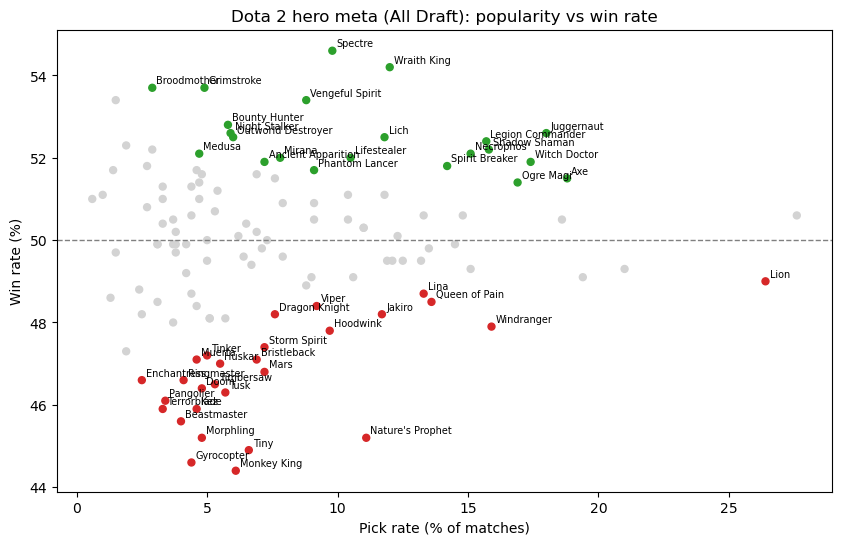

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = stats["verdict"].map({"strong": "tab:green", "weak": "tab:red", "balanced": "lightgrey"})
ax.scatter(stats["pick_rate_%"], stats["win_rate_%"], c=colors, s=25)
ax.axhline(50, color="grey", linestyle="--", linewidth=1)
for _, r in stats[stats["verdict"] != "balanced"].iterrows():
    ax.annotate(r["hero_name"], (r["pick_rate_%"], r["win_rate_%"]), fontsize=7,
                xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Pick rate (% of matches)")
ax.set_ylabel("Win rate (%)")
ax.set_title("Dota 2 hero meta (All Draft): popularity vs win rate")
plt.show()

# MG5: Summary of findings
## Summary: market and game analysis (real data)

**Data:** SteamCharts monthly players (copied once, cited), `palia_events.csv` (public
sources), and 72,915 public Dota 2 matches from OpenDota (Oct 2025 – Oct 2026, cleaned).
Not affiliated with Valve, Daybreak, Singularity 6 or EG7.

### Palia: update impact
- The PS5/Xbox launch with Elderwood (May 2025) raised average Steam players by 90%,
  and 3 months later the game was still 81% above its pre-launch level: a lasting step up.
- Royal Highlands (May 2026) brought a 56% spike, but players were back to the
  pre-release level within 3 months: a temporary boost.
- Without major content (Oct 2025 – Apr 2026), monthly players fell by about a third.
- Caveats: Steam only (no console players), overlapping events, correlation not proof.

### Dota 2: when and where people play
- Each region's share of matches peaks in its local evening: Europe 19–22 h CET,
  South America and North America around 21–23 h local time.
- Shares are relative: a region's share rises when others are asleep, so absolute
  peak hours require the hourly player-count data.

### Dota 2: match length and modes
- Turbo matches last about 25 minutes, about 40% shorter than standard (about 41 min).
- Standard matches get shorter with skill: 42.9 min (Herald) down to 38.4 min (Divine).
- Turbo is most popular in the middle ranks (about a third of matches) and least among
  Divine players (11%).

### Dota 2: hero meta (All Draft, 49,553 matches)
- Radiant side wins 53.1% of matches.
- 22 heroes significantly strong and 28 significantly weak (95% CI); about 6 would be
  expected by chance alone.
- Popularity and strength differ: Lion is picked in 26% of matches but wins 49%;
  Broodmother is picked in 3% but wins 54%.

### Limitations
- The match sample was taken at fixed hours, so match counts per hour don't measure
  activity; only the regional mix within each hour is meaningful.
- About 5% of matches come from servers not yet in OpenDota's region lists.
- Chinese servers are likely under-represented; no Immortal-level matches in the sample.
- Hero statistics average over a year of patches.

In [10]:
import os
OUT = "data/powerbi"
os.makedirs(OUT, exist_ok=True)

# 1. Monthly Steam players, both games
steam = sc.copy()
steam["month"] = pd.to_datetime(steam["month"]).dt.date
steam.to_csv(f"{OUT}/steam_monthly.csv", index=False)

# 2. Palia events and update impact
events.to_csv(f"{OUT}/palia_events.csv", index=False)
impact.rename(columns=lambda c: c.replace("%", "pct")).to_csv(f"{OUT}/palia_update_impact.csv", index=False)

# 3. Dota: regional mix per hour (long format)
region_mix = mix[cols].copy()
region_mix.columns.name = None
region_mix.rename_axis("hour_utc").reset_index() \
    .melt(id_vars="hour_utc", var_name="area", value_name="share_pct").round(2) \
    .to_csv(f"{OUT}/dota_region_mix.csv", index=False)

# 4. Dota: match length by medal and mode (with a number to sort medals correctly)
match_length = length.stack().rename("median_minutes").to_frame() \
    .join(count.stack().rename("matches")).reset_index()
match_length["medal_rank"] = match_length["medal"].map({v: k for k, v in MEDALS.items()})
match_length.to_csv(f"{OUT}/dota_match_length.csv", index=False)

# 5. Dota: hero stats
stats.reset_index().rename(columns=lambda c: c.replace("%", "pct")) \
    .to_csv(f"{OUT}/dota_hero_stats.csv", index=False)

# 6. Dota: all matches (interactive table)
fact_matches = d[["match_id", "start_time_utc", "hour_utc", "area", "region", "game_mode_name",
                  "lobby_type_name", "medal", "minutes", "radiant_win"]].copy()
fact_matches["medal_rank"] = fact_matches["medal"].map({v: k for k, v in MEDALS.items()})
fact_matches["minutes"] = fact_matches["minutes"].round(1)
fact_matches.to_csv(f"{OUT}/fact_dota_matches.csv", index=False)

print("Saved", len(os.listdir(OUT)), "files:", sorted(os.listdir(OUT)))

Saved 17 files: ['churn_timing.csv', 'daily_kpis.csv', 'dim_players.csv', 'dota_hero_stats.csv', 'dota_match_length.csv', 'dota_region_mix.csv', 'fact_dota_matches.csv', 'fact_purchases.csv', 'ltv_curve.csv', 'palia_events.csv', 'palia_update_impact.csv', 'retention_cohorts.csv', 'retention_curve.csv', 'retention_event_vs_normal.csv', 'segment_profile.csv', 'steam_monthly.csv', 'whale_curve.csv']
